# Phase 8: balance the training set

**The problem:** 88% of the training squares are `none`. A model that always says "no damage" is 88% accurate and useless.

**The fix:** shrink `none` **in train only**. Val and test keep the real mix, because real roads look like that.

**Key idea:** balance what the model *learns from*; keep what we *judge it on* realistic.

### Rules

| Rule | Value | Why |
|---|---|---|
| What we cut | only `none`, only in **train** | damage squares are rare, so all are kept; val/test must stay realistic |
| How many `none` to keep | **2 × the largest damage class** | **Assumption.** `none` is the most varied class (shadows, lane paint, manholes, cars), so the model needs plenty of it to avoid false alarms, but not so much that it drowns the damage. 2× keeps `none` the biggest class at a fraction of its size |
| Which `none` | random, seed 42 | same result every run |
| Class weights | `class_weight="balanced"` for softmax and SVM | evens out the classes that stay unequal. The MLP has no class weights, so for it the under-sampling does the job |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config

OUT = config.PROCESSED / "08_balance"
OUT.mkdir(exist_ok=True)
LABELS = config.CLASSES  # D00, D10, D20, D40, none
DAMAGE = LABELS[:4]
NAMES = {"D00": "D00 · Longitudinal crack", "D10": "D10 · Transverse crack", "D20": "D20 · Alligator crack",
         "D40": "D40 · Pothole", "none": "none · No damage"}
NONE_PER_DAMAGE = 2  # ASSUMPTION: keep 2 x the largest damage class of `none` (reasoned above)

patches = pd.read_csv(config.PROCESSED / "07_split" / "patches_split.csv")
train = patches[patches.split == "train"]
print(len(patches), "squares;", len(train), "in train")

240000 squares; 168000 in train


### 1. Count the labels in train only

In [2]:
before = train.label.value_counts().reindex(LABELS)
largest = before[DAMAGE].max()
print(f"largest damage class: {before[DAMAGE].idxmax()} with {largest:,} squares")
print(f"none is {before['none'] / before[DAMAGE].min():.0f}x the rarest class ({before[DAMAGE].idxmin()})")
pd.DataFrame({"squares": before, "share": (before / before.sum()).round(3)}).rename(index=NAMES)

largest damage class: D20 with 13,076 squares
none is 81x the rarest class (D10)


,squares,share
label,,
D00 · Longitudinal crack,3231,0.019
D10 · Transverse crack,1819,0.011
D20 · Alligator crack,13076,0.078
D40 · Pothole,2130,0.013
none · No damage,147744,0.879


### 2. Under-sample `none` to 2 × the largest damage class

In [3]:
def balance(train, none_per_damage):
    """Keep all damage squares, plus `none_per_damage x largest damage class` random none squares."""
    damage = train[train.label != "none"]
    n_none = int(none_per_damage * damage.label.value_counts().max())
    none = train[train.label == "none"].sample(n=min(n_none, (train.label == "none").sum()), random_state=config.SEED)
    return pd.concat([damage, none]).sort_index()


balanced = balance(train, NONE_PER_DAMAGE)
after = balanced.label.value_counts().reindex(LABELS)
assert (after[DAMAGE] == before[DAMAGE]).all(), "no damage square may be dropped"
print(f"none: {before['none']:,} -> {after['none']:,} (kept {after['none'] / before['none']:.1%});",
      f"train: {before.sum():,} -> {after.sum():,} squares")

none: 147,744 -> 26,152 (kept 17.7%); train: 168,000 -> 46,408 squares


**Before vs after** (train only). The damage bars do not move; only `none` shrinks, and it is still the biggest class.

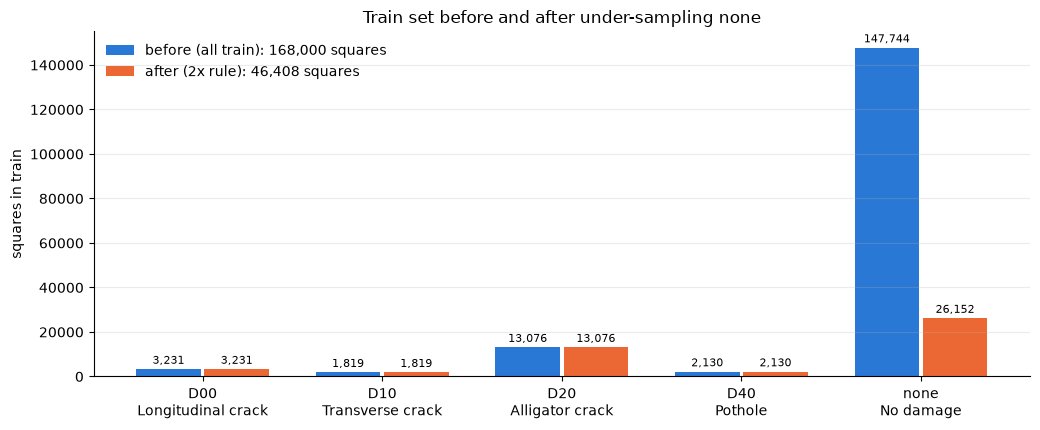

In [4]:
x = np.arange(len(LABELS))
w = 0.38
fig, ax = plt.subplots(figsize=(10.5, 4.4))
for i, (name, counts, color) in enumerate([("before (all train)", before, "#2a78d6"),
                                           (f"after ({NONE_PER_DAMAGE}x rule)", after, "#eb6834")]):
    bars = ax.bar(x + (i - 0.5) * w, counts, width=w - 0.02, color=color, label=f"{name}: {counts.sum():,} squares")
    ax.bar_label(bars, labels=[f"{v:,}" for v in counts], fontsize=8, padding=2)
ax.set_xticks(x, [NAMES[k].replace(" · ", "\n") for k in LABELS])
ax.set_ylabel("squares in train")
ax.set_title("Train set before and after under-sampling none")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

### 3. Class weights for softmax and SVM

The damage classes are still unequal (D20 is 7× D10). `class_weight="balanced"` gives each class `total ÷ (5 × its count)`, so a rare class counts more per square.

In [5]:
weights = compute_class_weight("balanced", classes=np.array(LABELS), y=balanced.label)
pd.DataFrame({"squares": after, "balanced weight": weights.round(2),
              "weight × squares": (weights * after).round(0)}).rename(index=NAMES)

,squares,balanced weight,weight × squares
label,,,
D00 · Longitudinal crack,3231,2.87,9282.0
D10 · Transverse crack,1819,5.10,9282.0
D20 · Alligator crack,13076,0.71,9282.0
D40 · Pothole,2130,4.36,9282.0
none · No damage,26152,0.35,9282.0


`weight × squares` is the same for every class: each class has the same total say in training, however many squares it has.

### 4. Save, and check val/test are untouched

In [6]:
balanced.to_csv(OUT / "train_balanced.csv", index=False)

for s in ["val", "test"]:  # these must still have the real mix: read them from 07, never from here
    assert (patches.split == s).sum() == {"val": 36000, "test": 36000}[s]
assert set(balanced.split) == {"train"}, "only train squares may be in the balanced file"
print(f"saved {len(balanced):,} train squares to {OUT.name}/train_balanced.csv;",
      "val and test stay in 07_split/patches_split.csv with the real mix")

saved 46,408 train squares to 08_balance/train_balanced.csv; val and test stay in 07_split/patches_split.csv with the real mix


### Findings

- `none` cut from 147,744 to **26,152** (17.7% kept). Train: 168,000 → **46,408** squares, every damage square kept. `none` is now 56% of train instead of 88%.
- Softmax and SVM get balanced weights (D10 5.10 … `none` 0.35). The MLP relies on the under-sampling alone.
- Saved to `08_balance/train_balanced.csv`. Val and test are untouched (real mix, in `07_split/patches_split.csv`).

**Why 2×:** we also tried 1×, 3×, 5× and no cut. 1× leaves too little clean road to learn from (more false alarms); 3× and more drift back towards `none` drowning the damage (`none` 66–88% of train). **2× is the best balance between the two**, so we keep it. Once the models are trained we confirm it with macro-F1 on val; changing it is one value, `NONE_PER_DAMAGE`.